# Tópicos de Big Data — Segundo examen parcial
## Examen práctico · Versión A

**Tiempo máximo:** 90 minutos  
**Calificación de este examen práctico:** 100 puntos (escala de 0 a 100)  
**Nombre:** César Alberto Cázares Chaván  
**Grupo:** 512  **Fecha:** 26/10/2026

### Situación de análisis
Se dispone de un conjunto de datos de viajes de taxi de Nueva York. Tu tarea consiste en aplicar **K-Means** para responder la siguiente pregunta:

> **¿Qué tipos de viajes pagados en efectivo se pueden identificar según la distancia recorrida y la duración del viaje?**

Trabajarás únicamente con los viajes cuyo tipo de pago sea **`Cash`** y utilizarás las variables **`trip_distance`** y **`trip_duration`**.

### Reglas de entrega
- Escribe tu propio código en las celdas vacías que aparecen después de cada instrucción.
- Ejecuta todas las celdas en orden y conserva las tablas y gráficas resultantes.
- Utiliza **Python, Pandas, NumPy, Matplotlib y scikit-learn**.
- No es necesario utilizar técnicas distintas de las estudiadas en clase.
- Guarda el archivo como **`Examen_A_Apellido_Nombre.ipynb`** y entrégalo con sus resultados visibles.
- El número de clústeres **no está predeterminado**: deberás seleccionarlo y justificarlo con evidencia.

**Ubicación obligatoria del dataset:** dentro de la carpeta de tu examen, guarda el archivo `nyc_taxi_examen.csv` en la subcarpeta `data/raw/`. La ruta relativa desde este notebook será **`data/raw/nyc_taxi_examen.csv`** (no es una ruta absoluta del sistema).

**Estructura de carpetas:**
```text
Examen_A/
└── notebooks/
    └── Examen_A_Apellido_Nombre.ipynb
└── data/
    └── raw/
        └── nyc_taxi_examen.csv
```

## 1. Carga y exploración de datos — 7 puntos · 10 minutos

**Escribe el código necesario para:**
1. Importar las bibliotecas que utilizarás.
2. Cargar el archivo CSV **`../data/raw/nyc_taxi_examen.csv`** en un DataFrame llamado `df`. La ruta es relativa a la carpeta donde está este notebook.
3. Mostrar las **primeras cinco filas**, las **dimensiones**, los **nombres de las columnas** y los **tipos de datos**.
4. Mostrar un resumen estadístico de las columnas numéricas.
5. Comprobar qué valores existen en la columna `payment_type`.

**Evidencia:** deja visibles los resultados de exploración.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ruta = "../data/raw/nyc_taxi_examen.csv"

# La primera columna del CSV es solo el número de fila, la uso como índice
df = pd.read_csv(ruta, index_col=0)

print("Primeras cinco filas:")
display(df.head())

print("Dimensiones:", df.shape)

print("\nNombres de las columnas:")
print(df.columns.tolist())

print("\nTipos de datos:")
print(df.dtypes)

Primeras cinco filas:


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
0,1,2026-08-01 00:03:04,2026-08-01 00:07:51,1.0,0.60,1.0,140.0,262.0,Credit card,6.5,3.5,0.5,2.30,0.00,1.0,13.80,2.5,0.0,0.00,4.783333
1,1,2026-08-01 00:38:45,2026-08-01 00:44:02,1.0,0.70,1.0,140.0,262.0,Credit card,6.5,3.5,0.5,3.45,0.00,1.0,14.95,2.5,0.0,0.00,5.283333
2,1,NaN,2026-08-01 01:01:07,100.0,1.10,1.0,140.0,263.0,Credit card,7.9,3.5,0.5,2.60,0.00,1.0,15.50,2.5,0.0,0.00,6.266667
3,1,2026-08-01 00:27:35,2026-08-01 00:54:27,1.0,5.24,1.0,164.0,80.0,Credit card,29.6,1.0,0.5,8.56,7.46,1.0,51.37,2.5,0.0,0.75,26.866667
4,2,2026-08-01 00:39:08,2026-08-01 01:00:23,1.0,3.57,1.0,148.0,141.0,Credit card,20.5,NaN,0.5,5.25,0.00,1.0,31.50,2.5,0.0,0.75,21.250000


Dimensiones: (2427612, 20)

Nombres de las columnas:
['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'cbd_congestion_fee', 'trip_duration']

Tipos de datos:
VendorID                   int64
tpep_pickup_datetime         str
tpep_dropoff_datetime        str
passenger_count          float64
trip_distance            float64
RatecodeID               float64
PULocationID             float64
DOLocationID             float64
payment_type                 str
fare_amount              float64
extra                    float64
mta_tax                  float64
tip_amount               float64
tolls_amount             float64
improvement_surcharge    float64
total_amount             float64
congestion_surcharge     float64
Airport_fee              

In [2]:
print("Resumen estadístico de las columnas numéricas:")
display(df.describe().round(2))

print("Valores de payment_type:")
df["payment_type"].value_counts(dropna=False)

Resumen estadístico de las columnas numéricas:


,VendorID,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
count,2427612.00,2415489.00,2415470.00,2415474.00,2415487.00,2415475.00,2415488.00,2415487.00,2415462.00,2415459.00,2415465.00,2415481.00,2415484.00,2415457.00,2415481.00,2415462.00,2415475.00
mean,1.89,1.30,3.30,4.23,164.14,163.22,38.53,1.57,0.48,3.67,0.59,0.99,29.38,2.25,0.20,0.56,15.61
std,0.81,1.88,5.17,17.20,62.85,69.26,542.38,1.91,0.10,4.23,2.39,0.16,25.93,0.78,0.63,0.33,260.58
min,1.00,-5.00,-99.99,1.00,1.00,1.00,-1849.60,-7.50,-0.50,-90.00,-106.46,-1.00,-1866.89,-2.50,-2.00,-0.75,-300517.52
25%,2.00,1.00,0.99,1.00,132.00,113.00,9.30,0.00,0.50,1.00,0.00,1.00,16.38,2.50,0.00,0.75,7.28
50%,2.00,1.00,1.70,1.00,161.00,162.00,13.50,1.00,0.50,2.95,0.00,1.00,21.54,2.50,0.00,0.75,12.32
75%,2.00,1.00,3.36,1.00,232.00,234.00,21.90,2.50,0.50,4.56,0.00,1.00,31.45,2.50,0.00,0.75,20.12
max,7.00,100.00,1686.49,99.00,265.00,265.00,19995.59,23.25,11.50,444.44,616.79,1.00,5530.74,2.75,27.00,0.75,8373.67


Valores de payment_type:


payment_type
Credit card    2051983
Cash            329533
Dispute          23558
NaN              12125
No charge        10413
Name: count, dtype: int64

## 2. Revisión y limpieza de datos — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Crear una copia de los datos originales llamada `df_limpio`.
2. Contar los **valores nulos por columna** y los **registros duplicados** antes de la limpieza.
3. Eliminar registros duplicados y filas que contengan valores nulos.
4. Conservar únicamente los registros que cumplan **todas** estas condiciones:
   - `trip_distance > 0`
   - `passenger_count > 0` y `passenger_count < 100`
   - `fare_amount > 0` y `fare_amount < 10000`
   - `trip_duration > 0`
5. Mostrar cuántos registros quedan después de limpiar.

**Importante:** no elimines registros por valores atípicos utilizando percentiles ni otros métodos adicionales. Si el archivo ya fue depurado, verifica igualmente estas condiciones.

**Evidencia:** muestra los conteos y las dimensiones antes y después de limpiar.

In [3]:
df_limpio = df.copy()

print("Dimensiones antes de limpiar:", df_limpio.shape)

print("\nValores nulos por columna:")
print(df_limpio.isnull().sum())

print("\nRegistros duplicados:", df_limpio.duplicated().sum())

# Elimino duplicados y filas con nulos
df_limpio = df_limpio.drop_duplicates()
df_limpio = df_limpio.dropna()

# Me quedo solo con los registros que cumplen todas las condiciones
df_limpio = df_limpio[
    (df_limpio["trip_distance"] > 0) &
    (df_limpio["passenger_count"] > 0) & (df_limpio["passenger_count"] < 100) &
    (df_limpio["fare_amount"] > 0) & (df_limpio["fare_amount"] < 10000) &
    (df_limpio["trip_duration"] > 0)
]

print("\nDimensiones después de limpiar:", df_limpio.shape)
print("Registros eliminados:", len(df) - len(df_limpio))
print("Nulos restantes:", df_limpio.isnull().sum().sum())
print("Duplicados restantes:", df_limpio.duplicated().sum())

Dimensiones antes de limpiar: (2427612, 20)

Valores nulos por columna:


VendorID                     0
tpep_pickup_datetime     12126
tpep_dropoff_datetime    12127
passenger_count          12123
trip_distance            12142
RatecodeID               12138
PULocationID             12125
DOLocationID             12137
payment_type             12125
fare_amount              12124
extra                    12125
mta_tax                  12150
tip_amount               12153
tolls_amount             12147
improvement_surcharge    12131
total_amount             12128
congestion_surcharge     12155
Airport_fee              12131
cbd_congestion_fee       12150
trip_duration            12137
dtype: int64



Registros duplicados: 11961



Dimensiones después de limpiar: (2096600, 20)
Registros eliminados: 331012


Nulos restantes: 0


Duplicados restantes: 0


## 3. Filtrado y selección de variables — 7 puntos · 5 minutos

**Escribe el código necesario para:**
1. Filtrar los registros de `df_limpio` donde `payment_type` sea exactamente **`Cash`**. Guarda el resultado en `df_cash`.
2. Seleccionar únicamente **`trip_distance`** y **`trip_duration`** para el agrupamiento. Guarda esas dos columnas en un DataFrame llamado `X`.
3. Mostrar la cantidad de viajes filtrados y las estadísticas descriptivas de `X`.

**Recuerda:** utiliza **únicamente estas dos variables** para entrenar K-Means.

**Evidencia:** cantidad de registros y tabla descriptiva.

In [4]:
df_cash = df_limpio[df_limpio["payment_type"] == "Cash"]

X = df_cash[["trip_distance", "trip_duration"]]

print("Viajes pagados en efectivo:", len(df_cash))
X.describe()

Viajes pagados en efectivo: 282085


,trip_distance,trip_duration
count,282085.000000,282085.000000
mean,3.842165,17.507243
std,6.214391,40.684025
min,0.010000,0.033333
25%,0.920000,7.400000
50%,1.700000,12.416667
75%,4.370000,20.883333
max,1686.490000,8373.666667


## 4. Transformación y estandarización — 14 puntos · 10 minutos

**Escribe el código necesario para:**
1. Aplicar `np.log1p()` a las dos variables de `X`. Guarda el resultado en `X_log`.
2. Crear un objeto `StandardScaler` y ajustar/transformar `X_log`.
3. Guardar los datos estandarizados en `X_escalado`.
4. Mostrar un resumen estadístico de las variables transformadas y estandarizadas para comprobar el resultado.

**Evidencia:** tabla con media, desviación estándar y otros estadísticos de las variables estandarizadas.

> La transformación logarítmica y la estandarización se aplican para el modelo; conserva `df_cash` con las unidades originales para interpretar los grupos al final.

In [5]:
X_log = np.log1p(X)

scaler = StandardScaler()
X_escalado = scaler.fit_transform(X_log)

# Lo paso a DataFrame para revisar el resumen con los nombres de las columnas
X_escalado_df = pd.DataFrame(X_escalado, columns=X.columns)

print("Variables con log1p:")
display(X_log.describe().round(3))

print("Variables con log1p y estandarizadas:")
X_escalado_df.describe().round(3)

Variables con log1p:


,trip_distance,trip_duration
count,282085.000,282085.000
mean,1.225,2.608
std,0.763,0.744
min,0.010,0.033
25%,0.652,2.128
50%,0.993,2.596
75%,1.681,3.086
max,7.431,9.033


Variables con log1p y estandarizadas:


,trip_distance,trip_duration
count,282085.000,282085.000
mean,0.000,-0.000
std,1.000,1.000
min,-1.592,-3.459
25%,-0.751,-0.644
50%,-0.304,-0.015
75%,0.597,0.642
max,8.130,8.631


## 5. Evaluación del número de clústeres — 21 puntos · 20 minutos

**Escribe el código necesario para:**
1. Evaluar los valores de **`k = 2, 3, 4, 5 y 6`** mediante un ciclo.
2. Para cada valor de `k`, entrenar `KMeans` con `random_state=42` y `n_init=10`.
3. Calcular y almacenar la **inercia** (`inertia_`).
4. Calcular y almacenar el **coeficiente de silueta** con `silhouette_score`, usando `sample_size=5000` y `random_state=42` para que el cálculo sea manejable.
5. Construir y mostrar una **tabla comparativa** con las columnas `k`, `Inercia` y `Silueta`.
6. Generar **dos gráficas separadas**: una para el método del codo y otra para el coeficiente de silueta. Ambas deben tener título y etiquetas en los ejes.

**Evidencia:** tabla y dos gráficas.

**Nota:** una inercia menor no basta por sí sola para elegir `k`; considera también la silueta y la interpretación de los grupos.

,k,Inercia,Silueta
0,2,227681.2292,0.5320
1,3,137511.9588,0.4478
2,4,100620.1949,0.4191
3,5,79205.3717,0.3894
4,6,66980.3104,0.3737


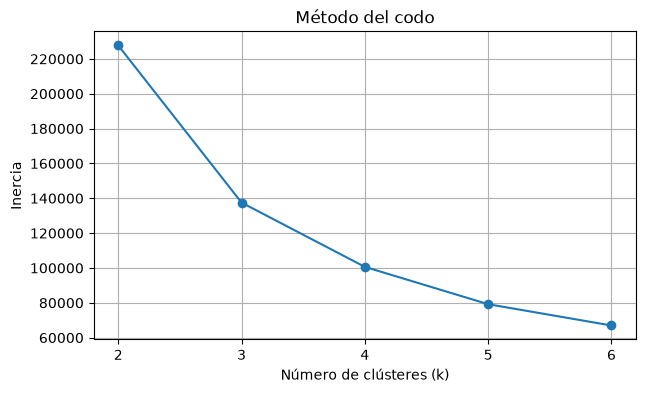

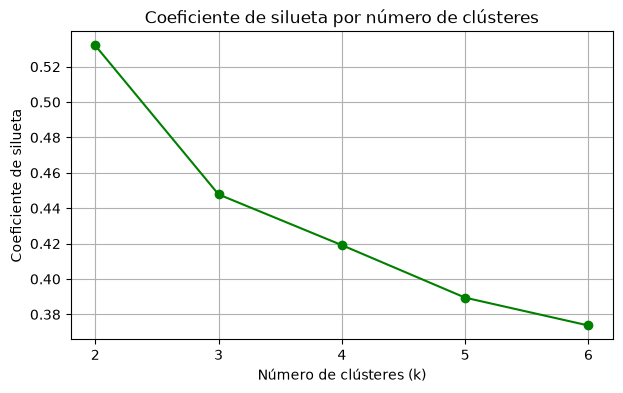

In [6]:
valores_k = [2, 3, 4, 5, 6]
inercias = []
siluetas = []

for k in valores_k:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = modelo.fit_predict(X_escalado)
    inercias.append(modelo.inertia_)
    siluetas.append(silhouette_score(X_escalado, etiquetas, sample_size=5000, random_state=42))

tabla_k = pd.DataFrame({"k": valores_k, "Inercia": inercias, "Silueta": siluetas})
display(tabla_k.round(4))

# Método del codo
plt.figure(figsize=(7, 4))
plt.plot(valores_k, inercias, marker="o")
plt.title("Método del codo")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Inercia")
plt.xticks(valores_k)
plt.grid(True)
plt.show()

# Coeficiente de silueta
plt.figure(figsize=(7, 4))
plt.plot(valores_k, siluetas, marker="o", color="green")
plt.title("Coeficiente de silueta por número de clústeres")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Coeficiente de silueta")
plt.xticks(valores_k)
plt.grid(True)
plt.show()

## 6. Modelo final y visualización — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Elegir un valor de `k` a partir de los resultados anteriores.
2. Entrenar un modelo final `KMeans` con ese valor, `random_state=42` y `n_init=10`.
3. Obtener las etiquetas de clúster para cada viaje.
4. Generar una **gráfica de dispersión** usando las dos columnas de `X_escalado`: eje X = **`trip_distance`**, eje Y = **`trip_duration`**, ambas transformadas y estandarizadas.
5. Colorear los puntos según el clúster asignado.
6. Dibujar los **centroides** del modelo con marcadores **X** de tamaño visible y un color que contraste.
7. Agregar título, nombres de ejes y leyenda de centroides.

**Evidencia:** gráfica final con clústeres y centroides.

**Nota sobre la visualización:** la gráfica debe mostrar los datos y centroides **transformados y estandarizados**, tal como los utiliza K-Means. Los valores de sus ejes no representan directamente las unidades originales.

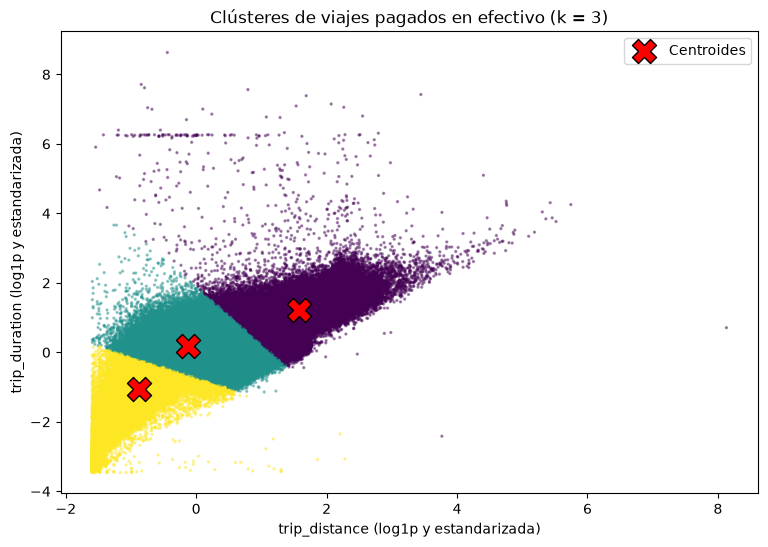

In [7]:
k_final = 3

modelo_final = KMeans(n_clusters=k_final, random_state=42, n_init=10)
etiquetas_final = modelo_final.fit_predict(X_escalado)
centroides = modelo_final.cluster_centers_

plt.figure(figsize=(9, 6))
plt.scatter(X_escalado[:, 0], X_escalado[:, 1], c=etiquetas_final, cmap="viridis", s=2, alpha=0.4)
plt.scatter(centroides[:, 0], centroides[:, 1], c="red", marker="X", s=300,
            edgecolors="black", label="Centroides")
plt.title(f"Clústeres de viajes pagados en efectivo (k = {k_final})")
plt.xlabel("trip_distance (log1p y estandarizada)")
plt.ylabel("trip_duration (log1p y estandarizada)")
plt.legend()
plt.show()

## 7. Estadísticos de los clústeres y preguntas de análisis — 23 puntos · 15 minutos

**Parte A. Tabla de estadísticos — 11 puntos**

**Importante:** calcula los estadísticos descriptivos usando los **datos originales de las variables, sin aplicarles la transformación logarítmica ni la estandarización**. Usa las etiquetas del modelo para agrupar los registros, pero toma los valores de `df_cash`, no de `X_escalado`.

**Escribe el código necesario para:**
1. Crear un DataFrame llamado `df_resultado` a partir de `df_cash`.
2. Agregar una columna `cluster` con las etiquetas obtenidas en el modelo final.
3. Agrupar por `cluster` y calcular, para cada grupo:
   - **Cantidad de viajes**.
   - **Media y mediana** de `trip_distance`.
   - **Media y mediana** de `trip_duration`.
4. Mostrar la tabla con valores redondeados a dos decimales. Los resultados deben expresarse en sus **unidades originales**: millas para la distancia y minutos para la duración.

**Evidencia:** tabla de estadísticos por clúster.

In [8]:
df_resultado = df_cash.copy()
df_resultado["cluster"] = etiquetas_final

tabla_clusters = df_resultado.groupby("cluster").agg(
    cantidad_viajes=("trip_distance", "count"),
    distancia_media_millas=("trip_distance", "mean"),
    distancia_mediana_millas=("trip_distance", "median"),
    duracion_media_min=("trip_duration", "mean"),
    duracion_mediana_min=("trip_duration", "median"),
)

tabla_clusters.round(2)

,cantidad_viajes,distancia_media_millas,distancia_mediana_millas,duracion_media_min,duracion_mediana_min
cluster,,,,,
0,62395,11.55,9.81,39.48,31.40
1,125521,2.30,1.94,15.43,14.00
2,94169,0.80,0.76,5.72,5.82


**Parte B. Preguntas de análisis — 12 puntos (3 puntos por pregunta).** Responde las cuatro preguntas con tus propias palabras. Usa las métricas, la gráfica y la tabla de estadísticos como evidencia. No basta con mencionar el número de clúster.

**Pregunta 1 — Selección de k.** ¿Qué valor de `k` elegiste y por qué? Justifica tu decisión utilizando **inercia, silueta** y, si corresponde, la claridad de los grupos obtenidos.

**Respuesta:**

Elegí k = 3. En la gráfica del codo la inercia baja mucho al pasar de 2 a 3 clústeres (de 227,681 a 137,512, unos 90 mil menos), pero a partir de 3 la caída ya es más pequeña: de 3 a 4 baja unos 37 mil, de 4 a 5 unos 21 mil y de 5 a 6 solo unos 12 mil. Por eso considero que el codo está en k = 3.

La silueta más alta la tiene k = 2 (0.532), pero con dos grupos solo separo viajes cortos y largos, lo cual me dice poco. Con k = 3 la silueta es de 0.448, que sigue siendo aceptable y es mejor que la de k = 4, 5 y 6. Además, en la gráfica de dispersión los tres grupos ocupan zonas distintas y cada uno tiene una interpretación clara (viajes muy cortos, intermedios y largos), así que me pareció el mejor balance entre las dos métricas.

**Pregunta 2 — Interpretación de grupos.** Describe las características de **cada clúster** a partir de la cantidad de viajes, las medias y las medianas. Asigna a cada grupo un nombre descriptivo.

**Respuesta:**

- **Clúster 2: viajes muy cortos.** Son 94,169 viajes. La distancia media es de 0.80 millas (mediana 0.76) y la duración media es de 5.72 minutos (mediana 5.82). Son trayectos de menos de una milla que se hacen en pocos minutos.
- **Clúster 1: viajes urbanos intermedios.** Es el grupo más grande con 125,521 viajes. La distancia media es de 2.30 millas (mediana 1.94) y la duración media es de 15.43 minutos (mediana 14.00). Son los traslados normales dentro de la ciudad.
- **Clúster 0: viajes largos.** Son 62,395 viajes, el grupo más pequeño. La distancia media es de 11.55 millas (mediana 9.81) y la duración media es de 39.48 minutos (mediana 31.40). Aquí deben estar viajes entre distritos o hacia aeropuertos. En este grupo la media está bastante por encima de la mediana, tanto en distancia como en duración, lo que indica que tiene algunos viajes extremos. Por ejemplo, los máximos que aparecen en la tabla descriptiva de X (1,686.49 millas y 8,373.67 minutos) quedaron en este grupo; no los quité porque el examen pide no eliminar atípicos.

**Pregunta 3 — Análisis sencillo.** ¿Qué clúster presenta la mayor duración promedio? ¿También tiene la mayor distancia promedio? Explica usando la tabla.

**Respuesta:**

El clúster 0 tiene la mayor duración promedio, con 39.48 minutos, contra 15.43 del clúster 1 y 5.72 del clúster 2. Ese mismo clúster también tiene la mayor distancia promedio, con 11.55 millas, mucho más que las 2.30 y 0.80 millas de los otros dos. Esto tiene sentido porque en la tabla las dos variables crecen juntas: entre más largo es el recorrido, más tiempo dura el viaje. Aun así, la duración no crece en la misma proporción que la distancia: el clúster 0 recorre unas 5 veces la distancia del clúster 1 pero tarda unas 2.5 veces más, posiblemente porque los viajes largos usan vías más rápidas.

**Pregunta 4 — Análisis sencillo.** ¿Cuál es el grupo más numeroso? ¿Qué características de distancia y duración predominan en ese grupo?

**Respuesta:**

El grupo más numeroso es el clúster 1, con 125,521 viajes, que es aproximadamente el 44.5% de los 282,085 viajes pagados en efectivo. En este grupo predominan los viajes intermedios dentro de la ciudad: la distancia mediana es de 1.94 millas y la duración mediana es de 14 minutos. Esto me indica que la mayoría de las personas que pagan en efectivo usan el taxi para trayectos de distancia corta a moderada, de alrededor de 2 millas y un cuarto de hora.


---
### Lista de verificación antes de entregar

- [x] Se muestran la carga, exploración, limpieza y filtrado.
- [x] Se utilizaron las **dos variables indicadas**.
- [x] Se aplicaron `log1p` y `StandardScaler`.
- [x] Se calcularon inercia y silueta para `k = 2...6`.
- [x] Se muestran la tabla de métricas y las dos gráficas de evaluación.
- [x] Se visualizan los clústeres y sus centroides.
- [x] Se presenta la tabla de estadísticos calculados sobre los **datos originales**, sin transformación ni estandarización, en sus unidades correspondientes.
- [x] Se respondieron las cuatro preguntas finales.

**Distribución de puntos (sobre 100):** carga y exploración: 7; limpieza: 14; filtrado y selección: 7; transformación y estandarización: 14; evaluación de k: 21; modelo y visualización: 14; estadísticos: 11; preguntas de análisis: 12. **Total: 100 puntos.**